<a href="https://colab.research.google.com/github/Reina-creator/MSSP607-GitHub/blob/main/WeeklyModules/Week13/Week13Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import subprocess
from pathlib import Path

owner = "Reina-creator"
repository = "MSSP607-GitHub"
repo_url = f"https://github.com/{owner}/{repository}.git"
repo_path = Path("/content") / repository

if not repo_path.exists():
    subprocess.run(["git", "clone", repo_url, str(repo_path)], check=True)
else:
    subprocess.run(["git", "-C", str(repo_path), "pull", "--ff-only"], check=True)

os.chdir(repo_path)
print("Current directory:", os.getcwd())

Current directory: /content/MSSP607-GitHub


In [2]:
%pip -q install -U yfinance

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.display import display

In [4]:
tickers = ["AAPL", "META", "GOOGL", "NFLX"]
companies = {symbol: yf.Ticker(symbol) for symbol in tickers}
stock_frames = {}

for symbol, company in companies.items():
    history = company.history(
        start="2023-01-01", end="2024-01-01",
        interval="1d", auto_adjust=False, actions=False
    )
    if history.empty:
        raise RuntimeError(f"Yahoo Finance returned no price history for {symbol}. Try again later.")
    history.index = history.index.tz_localize(None)
    history.index.name = "Date"
    stock_frames[symbol] = history.reset_index()
    print(f"{symbol}: {len(history)} trading days")

df_apple, df_facebook, df_google, df_netflix = [
    stock_frames[symbol] for symbol in tickers
]
display(df_apple.head())

AAPL: 250 trading days
META: 250 trading days
GOOGL: 250 trading days
NFLX: 250 trading days


,Date,Open,High,Low,Close,Adj Close,Volume
0,2023-01-03,130.279999,130.899994,124.169998,125.070000,122.783447,112117500
1,2023-01-04,126.889999,128.660004,125.080002,126.360001,124.049850,89113600
2,2023-01-05,127.129997,127.769997,124.760002,125.019997,122.734360,80962700
3,2023-01-06,126.010002,130.289993,124.889999,129.619995,127.250237,87754700
4,2023-01-09,130.470001,133.410004,129.889999,130.149994,127.770584,70790800


## Task 2:  Join the individual stock data frames into a single data frame.

Stack the individual tables and keep Date and Ticker as regular columns.

In [5]:
combined = pd.concat(
    [stock_frames[symbol].assign(Ticker=symbol) for symbol in tickers],
    ignore_index=True
).sort_values(["Date", "Ticker"]).reset_index(drop=True)

display(combined.head())

,Date,Open,High,Low,Close,Adj Close,Volume,Ticker
0,2023-01-03,130.279999,130.899994,124.169998,125.070000,122.783447,112117500,AAPL
1,2023-01-03,89.589996,91.050003,88.519997,89.120003,88.279961,28131200,GOOGL
2,2023-01-03,122.820000,126.370003,122.279999,124.739998,123.556610,35528500,META
3,2023-01-03,29.806000,29.839001,28.870001,29.495001,29.495001,67640000,NFLX
4,2023-01-04,126.889999,128.660004,125.080002,126.360001,124.049850,89113600,AAPL


In [6]:
metrics = [
    "quickRatio", "currentRatio", "totalRevenue", "debtToEquity",
    "revenuePerShare", "returnOnAssets", "returnOnEquity", "grossProfits"
]

rows = []
for symbol, company in companies.items():
    try:
        info = company.get_info()
    except Exception as error:
        print(f"{symbol}: Yahoo Finance metrics unavailable ({error})")
        info = {}
    rows.append({metric: info.get(metric) for metric in metrics})

financials = pd.DataFrame(rows, index=tickers).apply(pd.to_numeric, errors="coerce")
display(financials)

,quickRatio,currentRatio,totalRevenue,debtToEquity,revenuePerShare,returnOnAssets,returnOnEquity,grossProfits
AAPL,0.827,1.023,478833999872,84.286,32.658,0.25868,1.42257,233602007040
META,1.669,1.903,241605001216,42.161,95.186,0.14577,0.32264,195782000640
GOOGL,2.512,2.786,471097999360,22.187,38.789,0.12743,0.44286,286698012672
NFLX,0.836,1.075,49734631424,59.857,11.860,0.17124,0.53463,25207793664


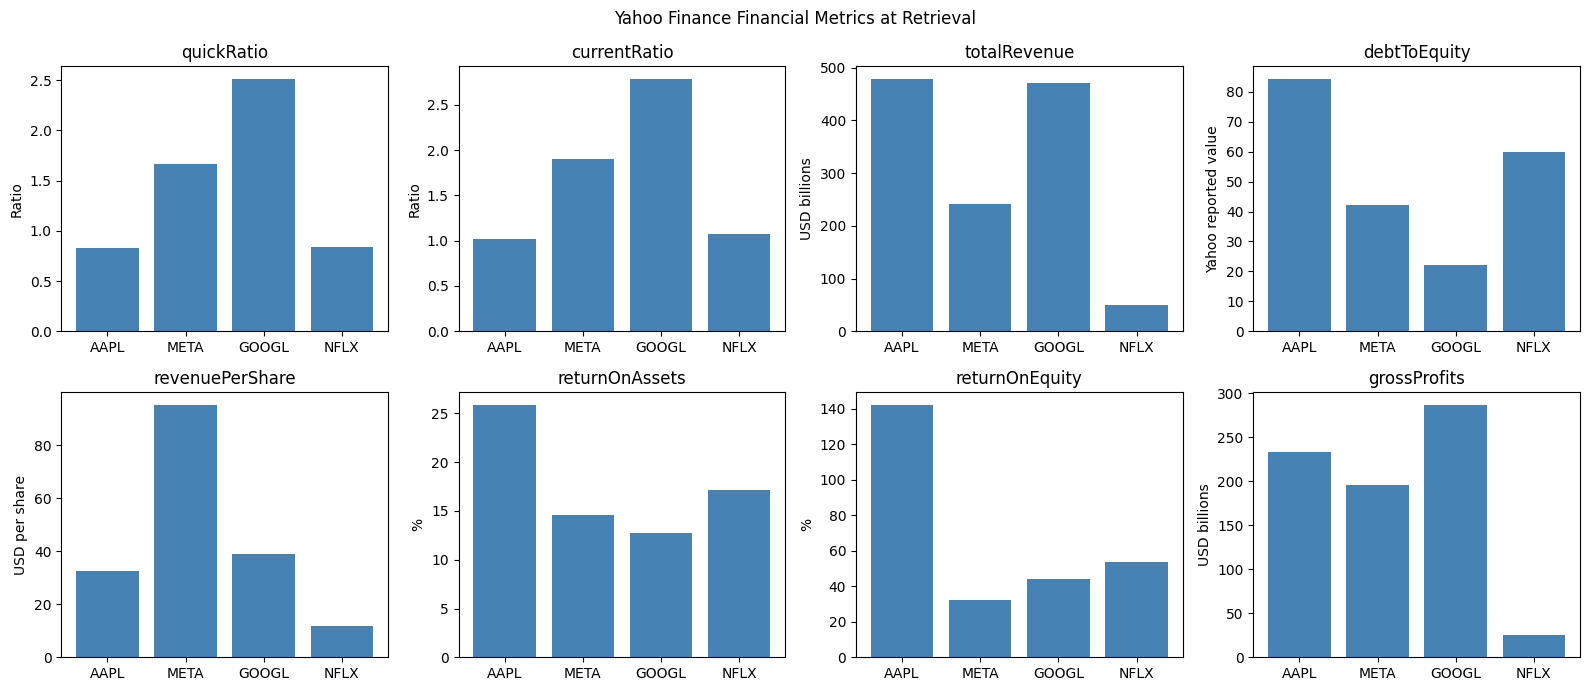

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for ax, metric in zip(axes.flat, metrics):
    values = financials[metric]
    unit = "Ratio"
    if metric in ["totalRevenue", "grossProfits"]:
        values = values / 1e9
        unit = "USD billions"
    elif metric in ["returnOnAssets", "returnOnEquity"]:
        values = values * 100
        unit = "%"
    elif metric == "revenuePerShare":
        unit = "USD per share"
    elif metric == "debtToEquity":
        unit = "Yahoo reported value"

    for position, symbol in enumerate(tickers):
        value = values.loc[symbol]
        if pd.notna(value):
            ax.bar(position, value, color="steelblue")
        else:
            ax.text(position, 0.05, "N/A", ha="center",
                    transform=ax.get_xaxis_transform())

    ax.set_xticks(range(len(tickers)), tickers)
    ax.set_title(metric)
    ax.set_ylabel(unit)
    ax.axhline(0, color="gray", linewidth=0.6)

fig.suptitle("Yahoo Finance Financial Metrics at Retrieval")
fig.tight_layout()
plt.show()

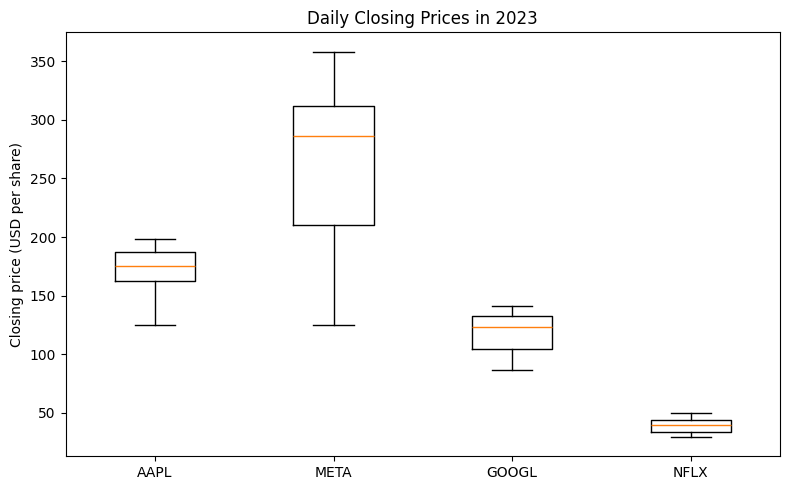

In [8]:
closing_prices = [stock_frames[symbol]["Close"].dropna() for symbol in tickers]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(closing_prices)
ax.set_xticks(range(1, len(tickers) + 1), tickers)
ax.set_title("Daily Closing Prices in 2023")
ax.set_ylabel("Closing price (USD per share)")
fig.tight_layout()
plt.show()

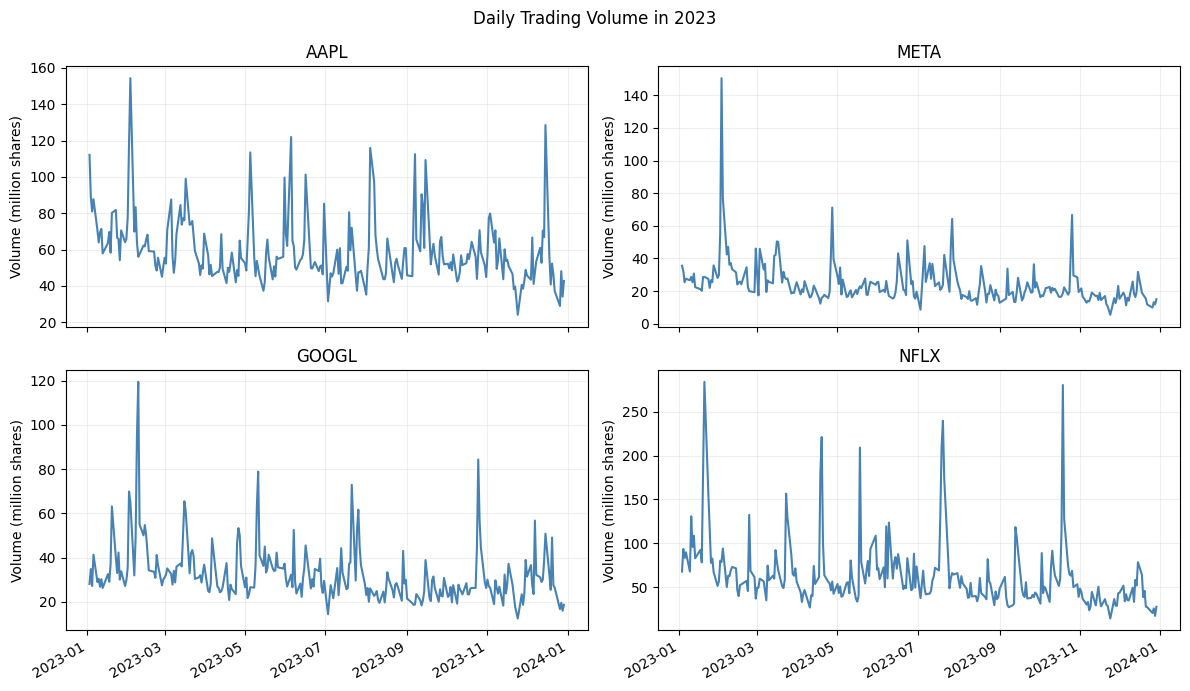

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)

for ax, symbol in zip(axes.flat, tickers):
    stock = stock_frames[symbol]
    ax.plot(stock["Date"], stock["Volume"] / 1_000_000, color="steelblue")
    ax.set_title(symbol)
    ax.set_ylabel("Volume (million shares)")
    ax.grid(alpha=0.2)

fig.suptitle("Daily Trading Volume in 2023")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()